# Week 2: Forecasting features, baselines and leakage prevention

This notebook uses the supplied PDF’s Python data-science workflow. Run cells in order. Model fitting and evaluation are real computations; the bundled source is clearly labelled synthetic practice data.

## Learn, practise, complete
**Topics:** forecast origin/horizon, historical lags, shifted rolling statistics, chronological partitions, naive/seasonal-naive forecasts, MAE/RMSE/bias/WAPE.

**YouTube:** [codebasics time series](https://www.youtube.com/@codebasics/search?query=time%20series%20forecasting), [StatQuest validation](https://www.youtube.com/@statquest/search?query=training%20validation%20testing).

**Websites:** [Forecasting textbook](https://otexts.com/fpp3/), [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

**Your task:** hand-check a seven-day seasonal forecast and a rolling mean. Explain why using actual observations from inside a future seven-day horizon is leakage. Keep final test results reserved.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT/'src/data.py').is_file(), 'Open this notebook from the project or notebooks folder.'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
from src.data import read_sales, source_info, file_hash

# Change this to a licensed canonical sales CSV for your own analysis.
DATA_PATH = ROOT/'data/raw/demo_sales.csv'
data = read_sales(DATA_PATH)
source = source_info(DATA_PATH)
print('DATA SOURCE:', source['data_kind'])
print('SOURCE SHA-256:', source['source_sha256'])
print('Bundled data is synthetic practice data, not real retail observations.')
display(data.head())

DATA SOURCE: synthetic practice; not observed retail sales
SOURCE SHA-256: c0f8a91575ec1819cb02c4783d23f8e7d3d172d1cd83fce572aaff57302c67fc
Bundled data is synthetic practice data, not real retail observations.


,date,store,item,sales
0,2022-01-01,1,1,32
1,2022-01-02,1,1,28
2,2022-01-03,1,1,18
3,2022-01-04,1,1,11
4,2022-01-05,1,1,16


## 1. Declare the seven-day task and chronological windows

In [2]:
from src.forecasting import FEATURES, make_training, split_windows, forecast_frame, baseline_report, metrics
windows=split_windows(data)
display(pd.Series({key:str(value) for key,value in windows.items() if not key.endswith('origins')}))
print('Each validation origin forecasts seven future days recursively; actual observations become available only between origins.')

train_end           2023-11-05 00:00:00
validation_start    2023-11-06 00:00:00
validation_end      2023-12-03 00:00:00
test_start          2023-12-04 00:00:00
test_end            2023-12-31 00:00:00
dtype: object

Each validation origin forecasts seven future days recursively; actual observations become available only between origins.


## 2. Inspect past-only lag, rolling and calendar features

In [3]:
features=make_training(data)
display(features[['date','store','item','sales','lag_1','lag_7','lag_14','mean_7','mean_28']].head(12))
processed=ROOT/'data/processed'
processed.mkdir(parents=True,exist_ok=True)
features.to_csv(processed/'features.csv',index=False)

,date,store,item,sales,lag_1,lag_7,lag_14,mean_7,mean_28
0,2022-01-29,1,1,30,24,23,27,20.142857,20.321429
1,2022-01-30,1,1,23,30,26,16,21.142857,20.250000
2,2022-01-31,1,1,12,23,18,12,20.714286,20.071429
3,2022-02-01,1,1,21,12,16,15,19.857143,19.857143
4,2022-02-02,1,1,10,21,13,21,20.571429,20.214286
5,2022-02-03,1,1,16,10,21,18,20.142857,20.000000
6,2022-02-04,1,1,24,16,24,26,19.428571,19.821429
7,2022-02-05,1,1,31,24,30,23,19.428571,19.892857
8,2022-02-06,1,1,27,31,23,26,19.571429,20.000000
9,2022-02-07,1,1,18,27,12,18,20.142857,20.000000


## 3. Demonstrate a feature-leakage check
Changing sales after an origin must not change the feature vector used to predict the next day. The next-day target itself can change; it is excluded from the comparison.

In [4]:
origin=windows['train_end']
changed=data.copy()
changed.loc[changed.date>origin,'sales'] += 1000
changed_features=make_training(changed)
day=origin+pd.Timedelta(days=1)
a=features.loc[features.date==day,FEATURES].reset_index(drop=True)
b=changed_features.loc[changed_features.date==day,FEATURES].reset_index(drop=True)
pd.testing.assert_frame_equal(a,b)
print('PASS: forecast-origin features do not depend on future targets.')

PASS: forecast-origin features do not depend on future targets.


## 4. Hand-check naive and seven-day seasonal-naive forecasts

In [5]:
key=next(iter(data.groupby(['store','item']).groups))
history=data[(data.store==key[0]) & (data.item==key[1]) & (data.date<=origin)]
naive=forecast_frame(history,7,'naive')
seasonal=forecast_frame(history,7,'seasonal_naive')
assert naive.prediction.tolist()==[float(history.sales.iloc[-1])]*7
assert seasonal.prediction.tolist()==history.sales.tail(7).astype(float).tolist()
display(pd.DataFrame({'date':naive.date,'naive':naive.prediction,'seasonal_naive':seasonal.prediction}))

,date,naive,seasonal_naive
0,2023-11-06,26.0,23.0
1,2023-11-07,26.0,17.0
2,2023-11-08,26.0,22.0
3,2023-11-09,26.0,17.0
4,2023-11-10,26.0,38.0
5,2023-11-11,26.0,42.0
6,2023-11-12,26.0,26.0


## 5. Evaluate baselines on validation only

In [6]:
baseline=baseline_report(DATA_PATH,ROOT/'reports/week02')
display(pd.DataFrame(baseline['validation_metrics']).T)
predictions=pd.read_csv(ROOT/'reports/week02/baseline_validation_predictions.csv',dtype={'store':str,'item':str})
predictions.to_csv(processed/'baseline_forecasts.csv',index=False)
grouped=predictions.groupby('model').apply(lambda group: pd.Series(metrics(group.actual,group.prediction)),include_groups=False)
display(grouped)

,mae,rmse,bias,wape_percent,n
naive,9.428571,11.467345,3.044643,24.985212,224.0
seasonal_naive,6.589286,8.227784,0.062500,17.461256,224.0


,mae,rmse,bias,wape_percent,n
model,,,,,
naive,9.428571,11.467345,3.044643,24.985212,224.0
seasonal_naive,6.589286,8.227784,0.062500,17.461256,224.0


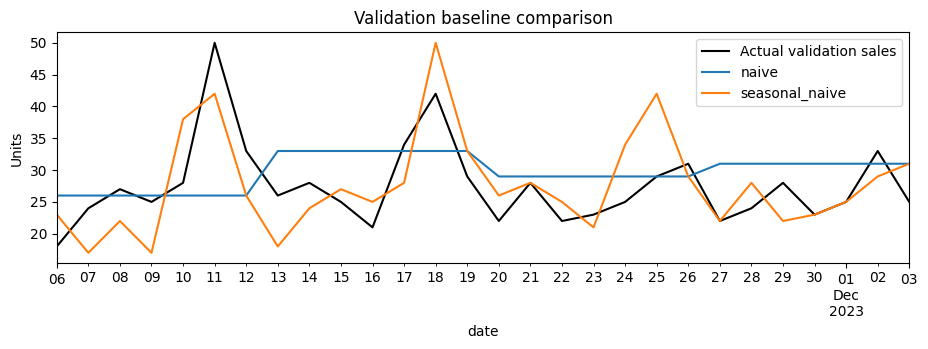

In [7]:
example=predictions[(predictions.store==key[0]) & (predictions.item==key[1])].copy()
example['date']=pd.to_datetime(example.date)
fig,ax=plt.subplots(figsize=(11,3))
example.drop_duplicates('date').plot(x='date',y='actual',ax=ax,color='black',label='Actual validation sales')
for method,group in example.groupby('model'):
    group.plot(x='date',y='prediction',ax=ax,label=method)
ax.set_ylabel('Units'); ax.set_title('Validation baseline comparison'); plt.show()

## 6. Understand metrics and the zero-demand case

In [8]:
print('Known example:',metrics([0,2],[1,0]))
assert metrics([0,2],[1,0])['mae']==1.5
assert metrics([0,0],[1,1])['wape_percent'] is None
print('WAPE is undefined when the total actual demand is zero; no fake percentage is substituted.')

Known example: {'mae': 1.5, 'rmse': 1.5811388300841898, 'bias': -0.5, 'wape_percent': 150.0, 'n': 2}
WAPE is undefined when the total actual demand is zero; no fake percentage is substituted.


## Your Week 2 submission
Commit the feature code, baseline report, chronological split explanation and hand-checked example. Explain the difference between rolling one-step evaluation and a genuine seven-day forecast. Do not select model settings from the final test results.